In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
RESULTS_DIR = "../results/2026-06-25_full_benchmark"

ENTROPY_PATH = os.path.join(
    RESULTS_DIR,
    "entropy",
    "entropy_results_by_sigma.csv"
)

SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "entropy",
    "entropy_summary_by_model.csv"
)

FIGURE_DIR = "../figures/entropy"

os.makedirs(FIGURE_DIR, exist_ok=True)

In [4]:
entropy_df = pd.read_csv(ENTROPY_PATH)

summary_df = pd.read_csv(SUMMARY_PATH)

entropy_df.head()

,series,model,sigma,n_samples,true_shannon_entropy,pred_shannon_entropy,delta_shannon_entropy,true_permutation_entropy,pred_permutation_entropy,delta_permutation_entropy
0,linear_gaussian,ar1,1.555556,496,0.928826,0.935993,0.007166,0.961985,0.962256,0.000270
1,linear_gaussian,ar1,1.777778,500,0.952230,0.953009,0.000778,0.971418,0.970646,0.000772
2,linear_gaussian,ar1,2.000000,500,0.864530,0.864414,0.000116,0.966152,0.966321,0.000169
3,linear_gaussian,causal_encoder_transformer,1.555556,496,0.928826,0.657780,0.271047,0.961985,0.945316,0.016669
4,linear_gaussian,causal_encoder_transformer,1.777778,500,0.952230,0.845825,0.106406,0.971418,0.958296,0.013122


In [5]:
MODEL_ORDER = [
    "naive",
    "drift_naive",
    "ar1",
    "xgboost_level",
    "xgboost_increment",
    "lstm_level",
    "lstm_increment",
    "gru_level",
    "tcn_level",
    "simple_causal_transformer",
    "residual_causal_transformer",
    "causal_encoder_transformer",
    "patchtst_level"
]

SERIES_ORDER = [
    "linear_gaussian",
    "linear_student_t",
    "nonlinear_gaussian",
    "nonlinear_student_t"
]

TOP_MODELS = [
    "naive",
    "lstm_increment",
    "residual_causal_transformer",
    "tcn_level",
    "xgboost_increment"
]

def model_label(name):
    return name.replace("_"," ").title()

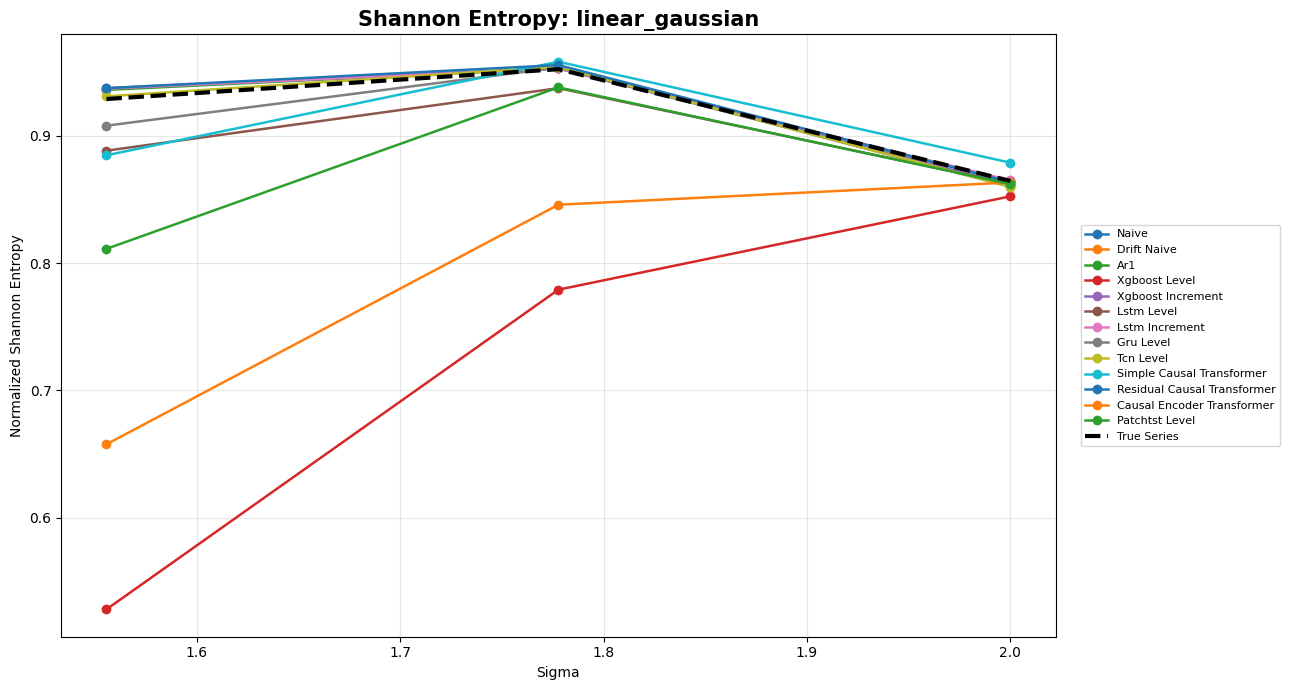

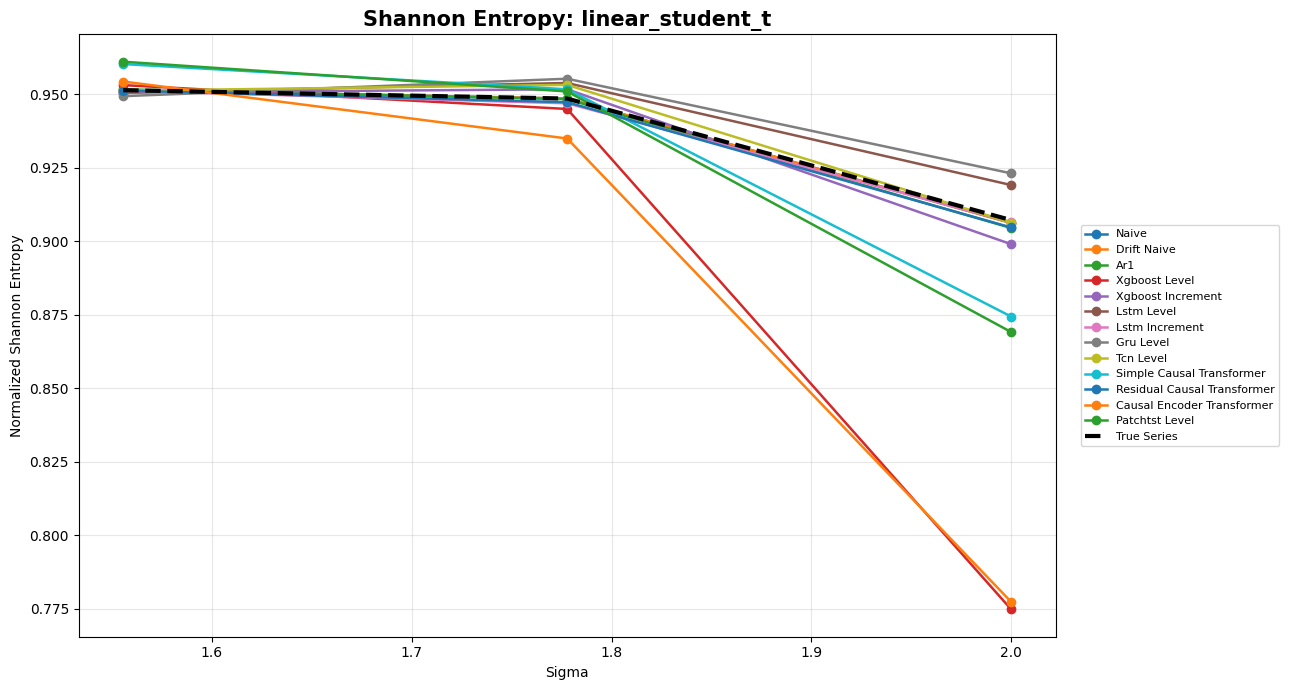

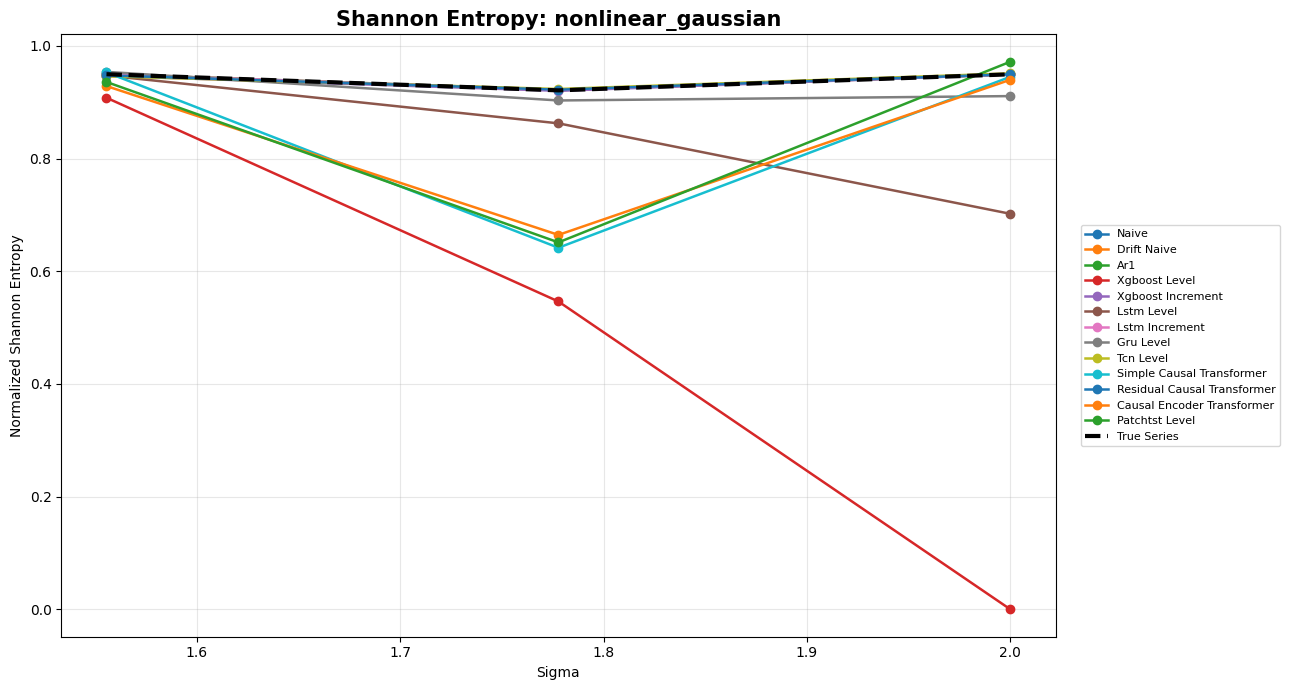

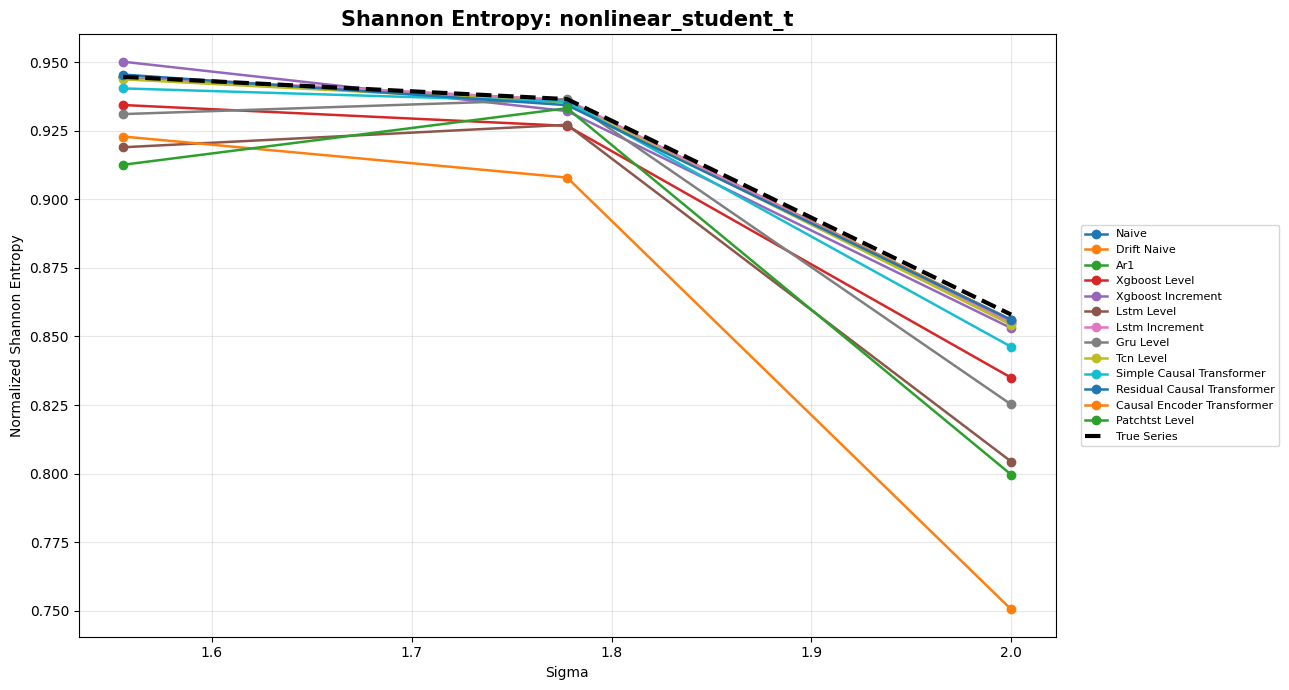

In [6]:
for series in SERIES_ORDER:

    subset = entropy_df[
        entropy_df["series"] == series
    ]

    plt.figure(figsize=(13,7))

    for model in MODEL_ORDER:

        temp = subset[
            subset["model"]==model
        ].sort_values("sigma")

        plt.plot(
            temp["sigma"],
            temp["pred_shannon_entropy"],
            marker="o",
            linewidth=1.8,
            label=model_label(model)
        )

    true_curve = (
        subset.groupby("sigma")
        ["true_shannon_entropy"]
        .mean()
    )

    plt.plot(
        true_curve.index,
        true_curve.values,
        color="black",
        linewidth=3,
        linestyle="--",
        label="True Series"
    )

    plt.title(
        f"Shannon Entropy: {series}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Sigma")
    plt.ylabel("Normalized Shannon Entropy")

    plt.grid(alpha=0.3)

    plt.legend(
        bbox_to_anchor=(1.02,0.5),
        loc="center left",
        fontsize=8
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            f"{series}_shannon_entropy.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

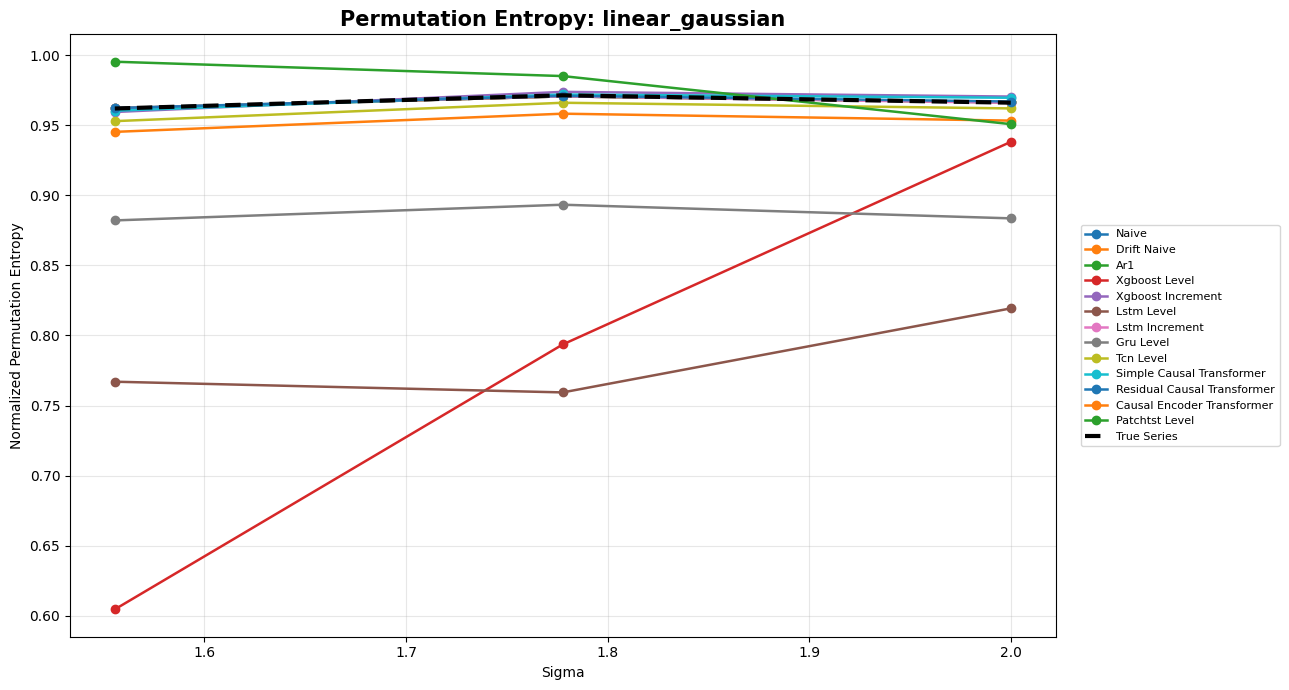

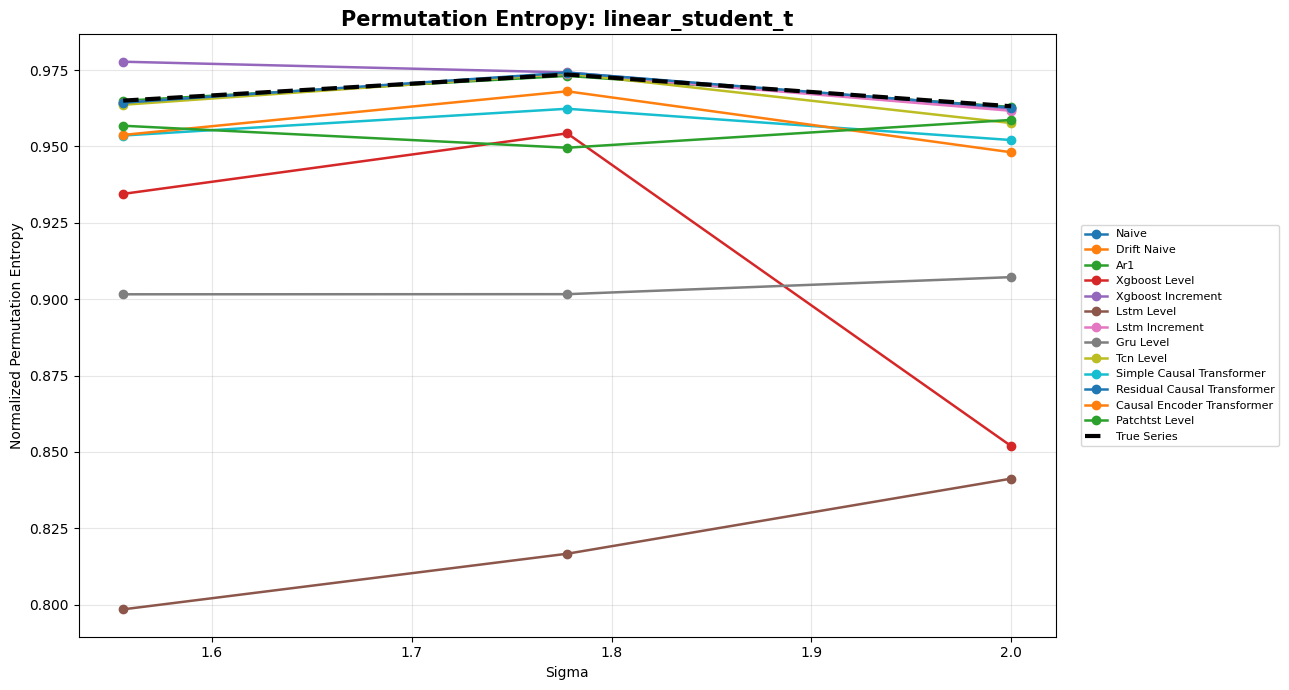

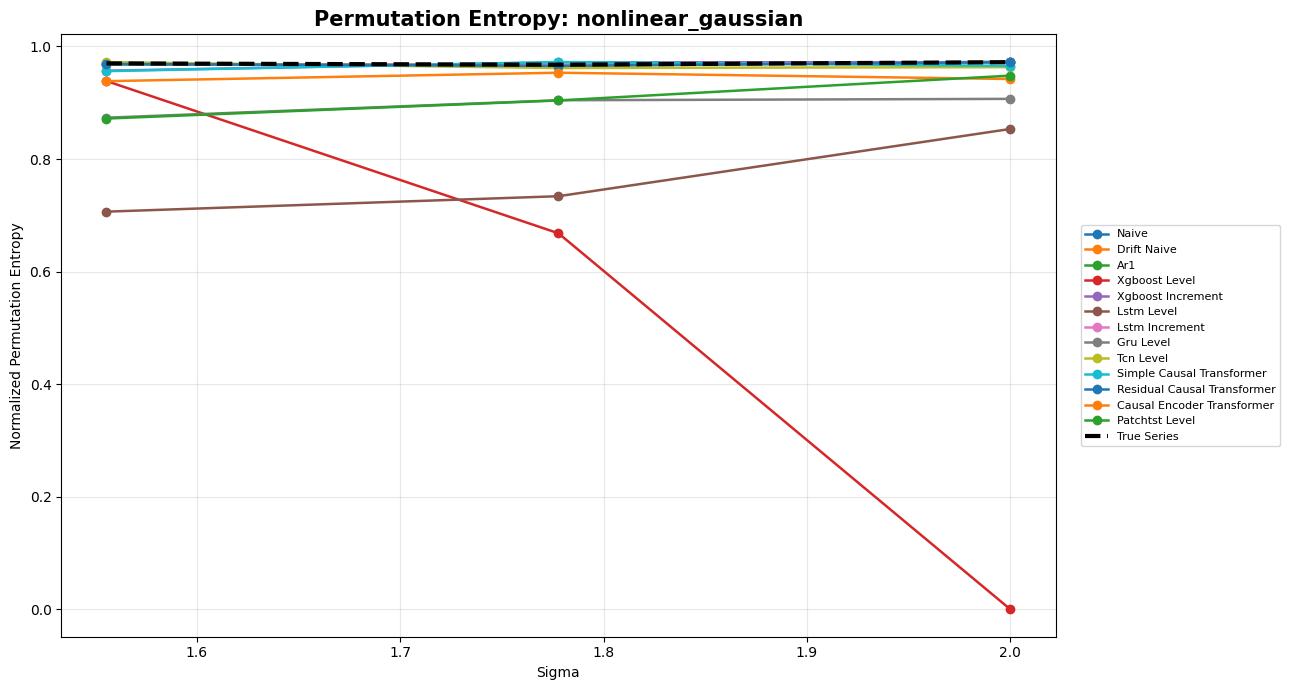

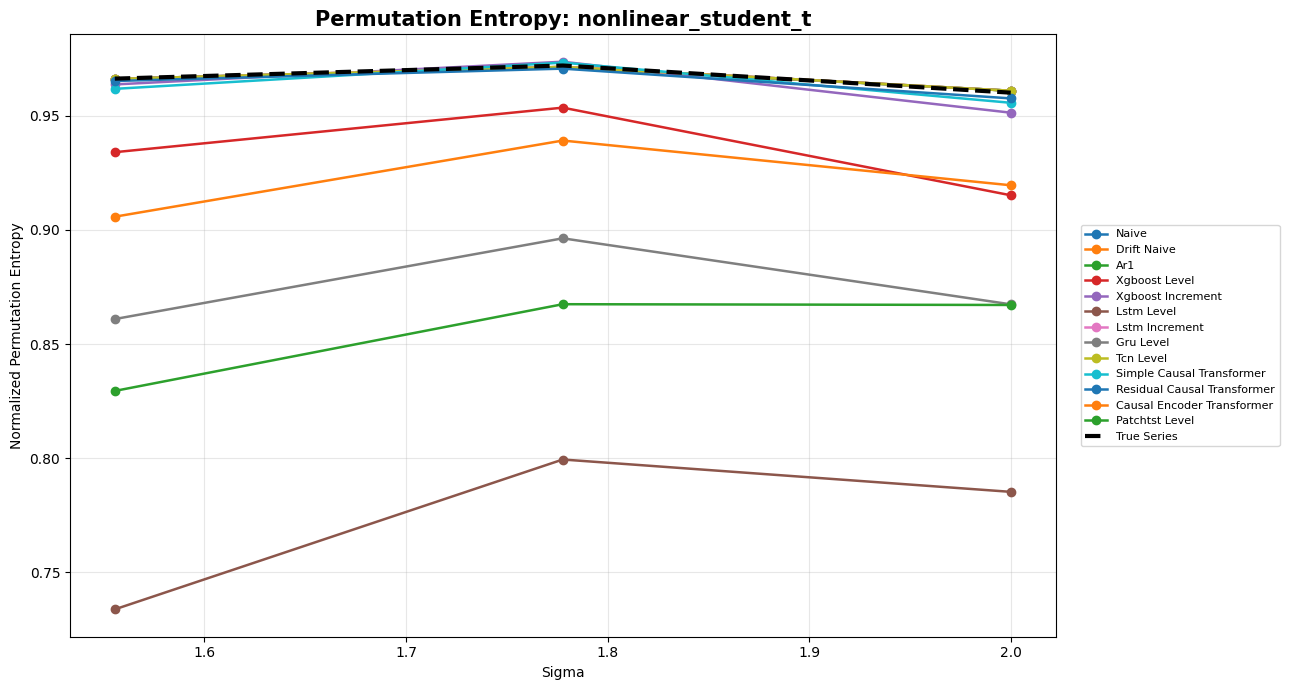

In [7]:
for series in SERIES_ORDER:

    subset = entropy_df[
        entropy_df["series"] == series
    ]

    plt.figure(figsize=(13,7))

    for model in MODEL_ORDER:

        temp = subset[
            subset["model"]==model
        ].sort_values("sigma")

        plt.plot(
            temp["sigma"],
            temp["pred_permutation_entropy"],
            marker="o",
            linewidth=1.8,
            label=model_label(model)
        )

    true_curve = (
        subset.groupby("sigma")
        ["true_permutation_entropy"]
        .mean()
    )

    plt.plot(
        true_curve.index,
        true_curve.values,
        color="black",
        linewidth=3,
        linestyle="--",
        label="True Series"
    )

    plt.title(
        f"Permutation Entropy: {series}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Sigma")
    plt.ylabel("Normalized Permutation Entropy")

    plt.grid(alpha=0.3)

    plt.legend(
        bbox_to_anchor=(1.02,0.5),
        loc="center left",
        fontsize=8
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            f"{series}_permutation_entropy.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

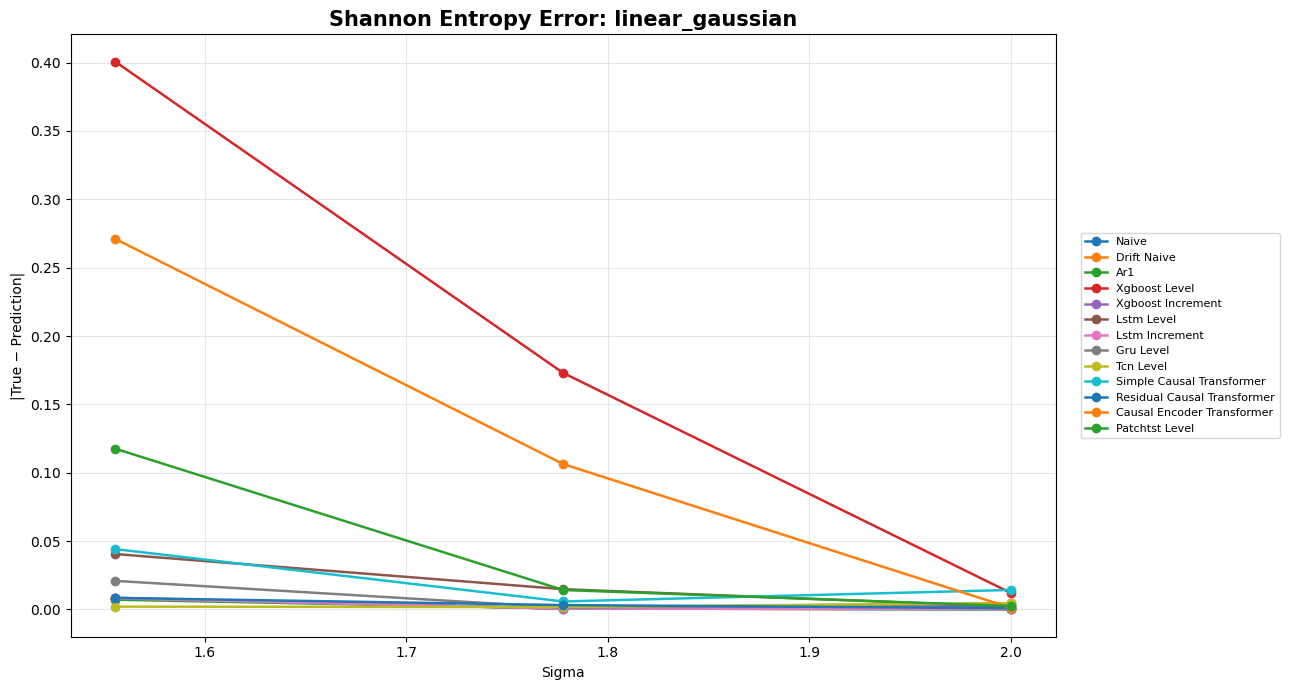

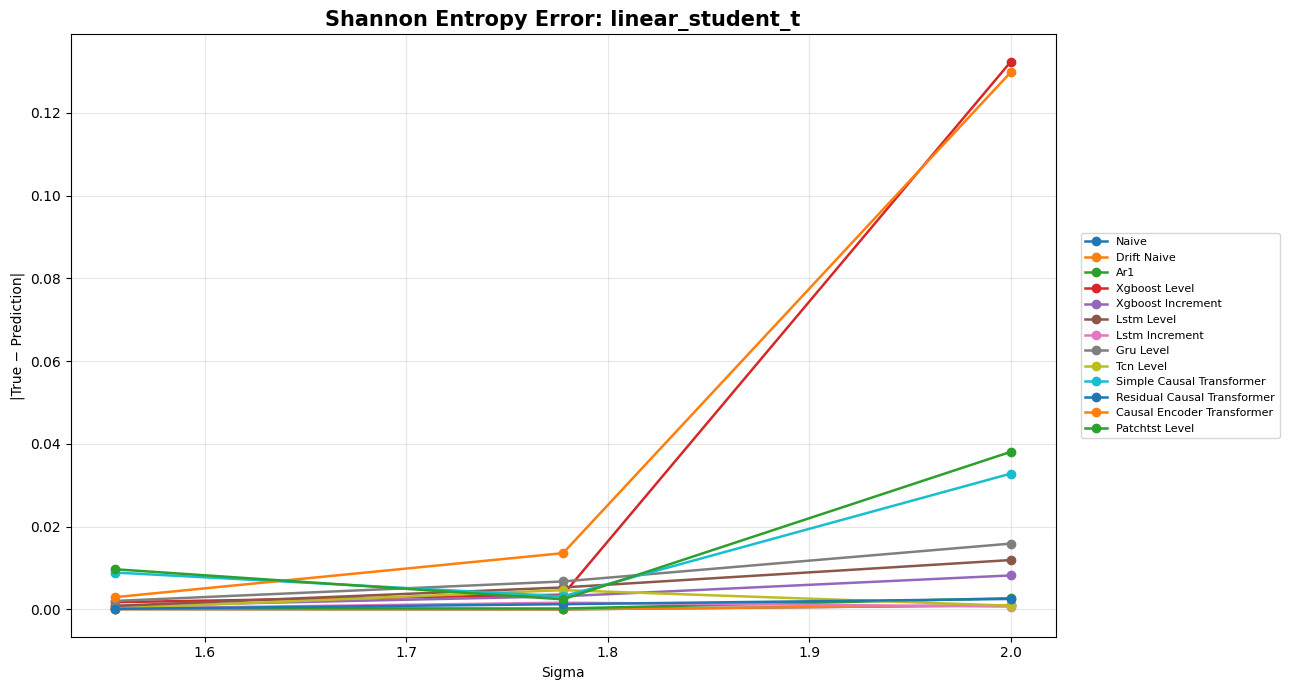

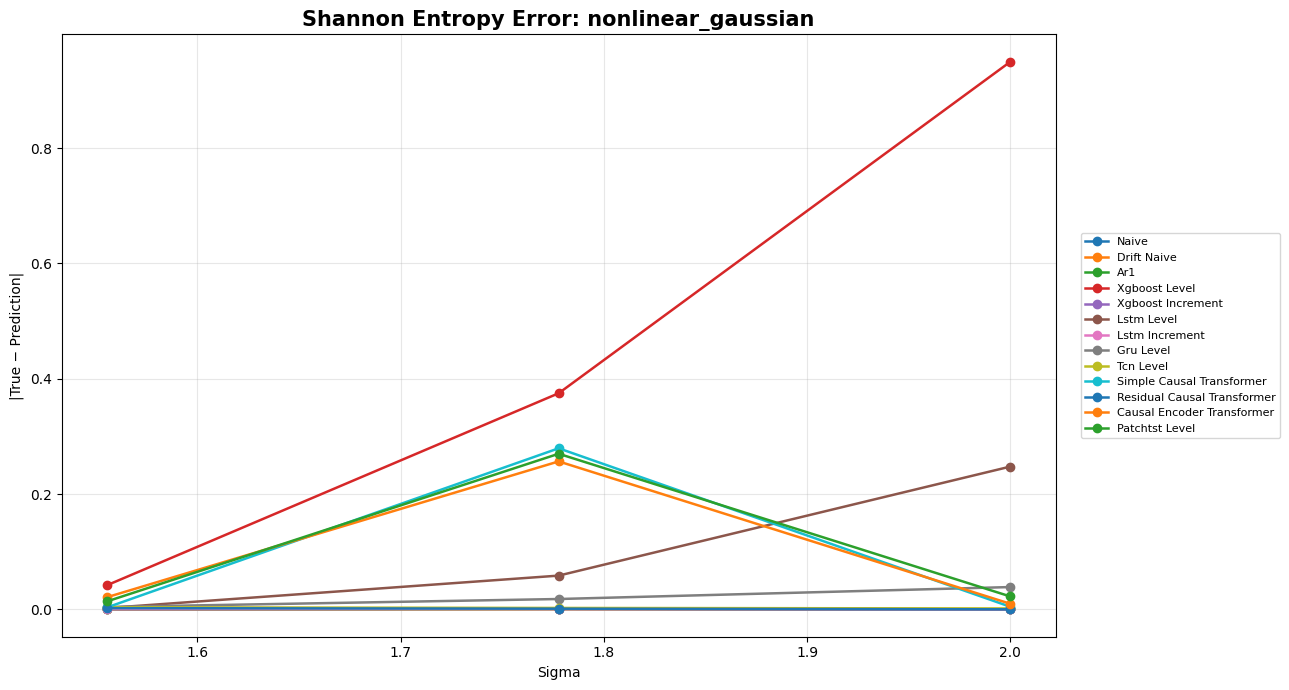

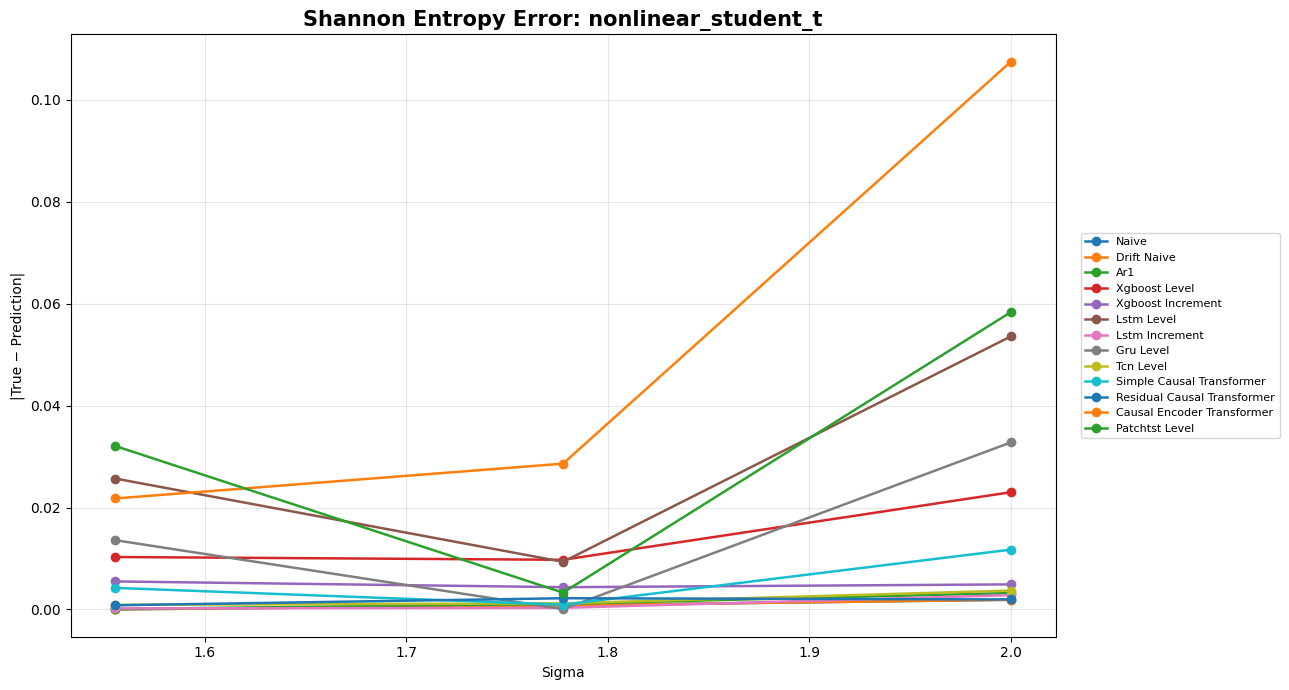

In [8]:
for series in SERIES_ORDER:

    subset = entropy_df[
        entropy_df["series"]==series
    ]

    plt.figure(figsize=(13,7))

    for model in MODEL_ORDER:

        temp = subset[
            subset["model"]==model
        ].sort_values("sigma")

        plt.plot(
            temp["sigma"],
            temp["delta_shannon_entropy"],
            marker="o",
            linewidth=1.8,
            label=model_label(model)
        )

    plt.title(
        f"Shannon Entropy Error: {series}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Sigma")
    plt.ylabel("|True − Prediction|")

    plt.grid(alpha=0.3)

    plt.legend(
        bbox_to_anchor=(1.02,0.5),
        loc="center left",
        fontsize=8
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            f"{series}_delta_shannon_entropy.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

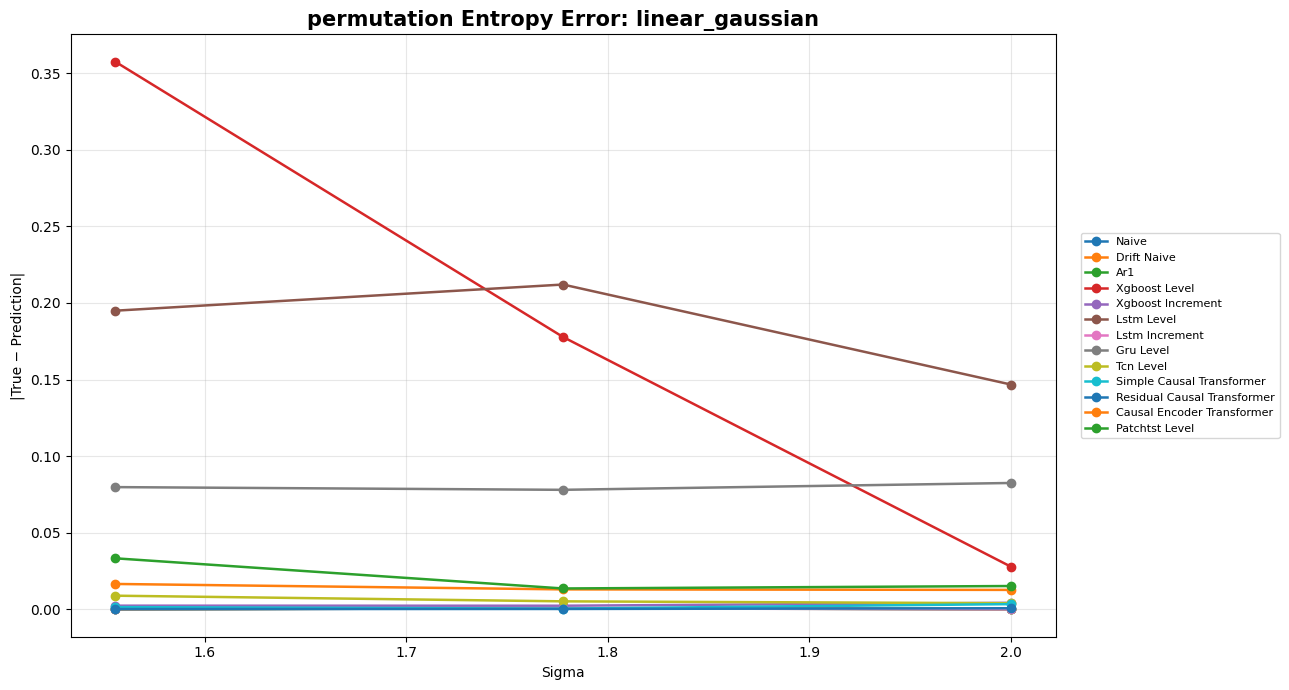

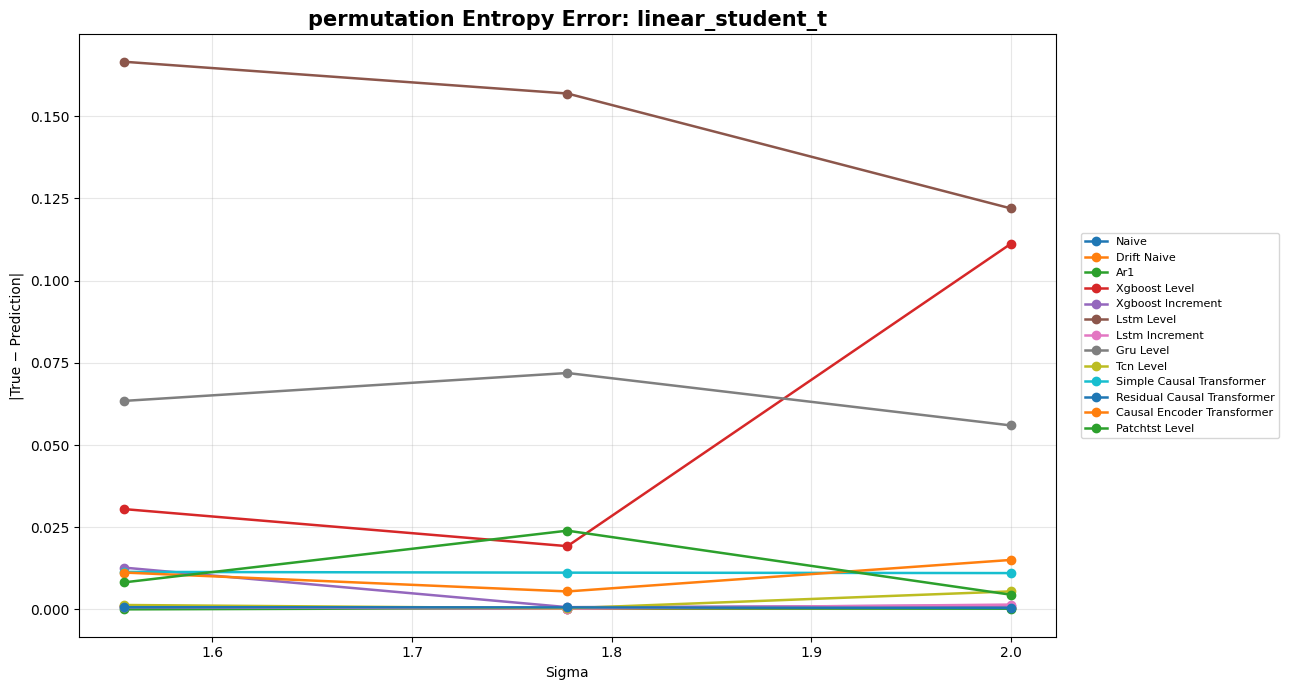

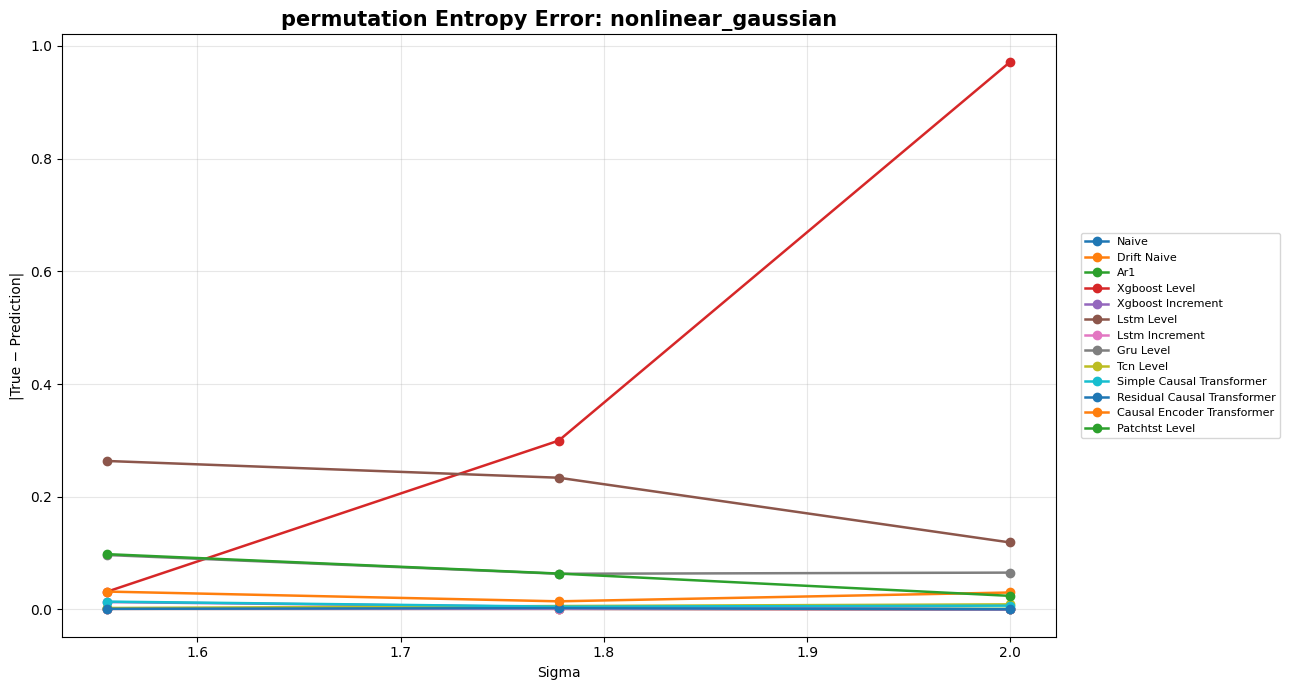

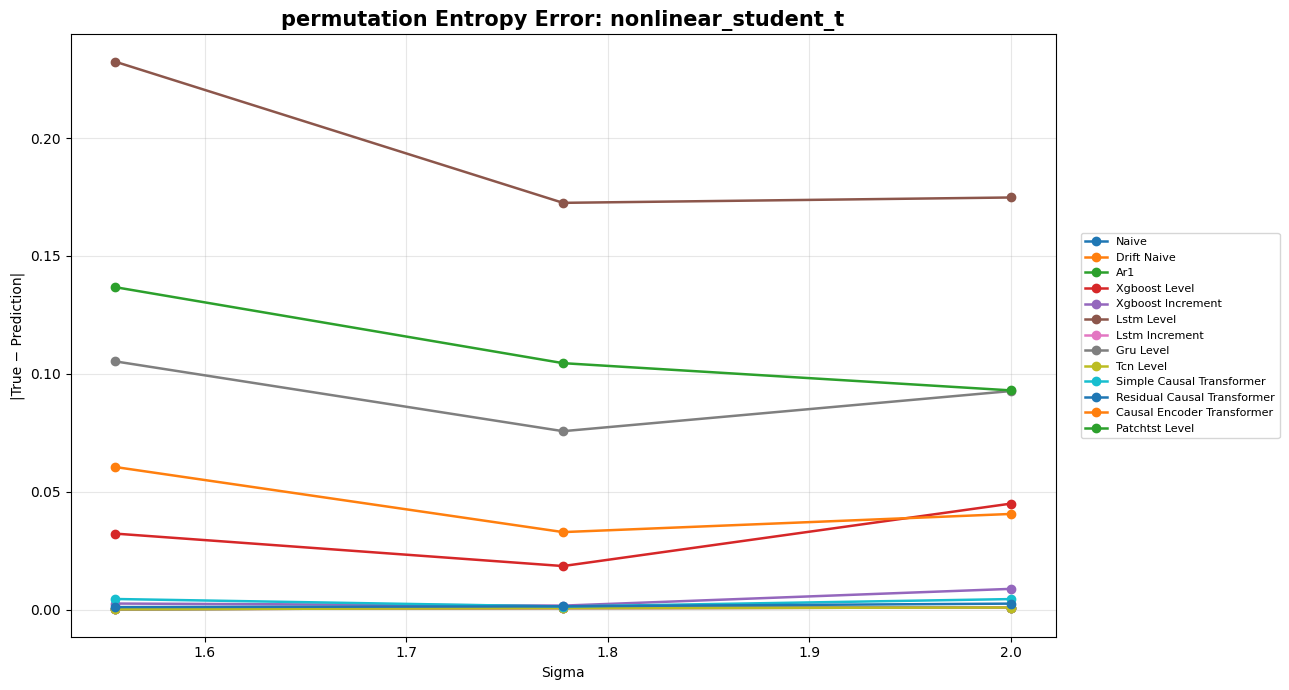

In [9]:
for series in SERIES_ORDER:

    subset = entropy_df[
        entropy_df["series"]==series
    ]

    plt.figure(figsize=(13,7))

    for model in MODEL_ORDER:

        temp = subset[
            subset["model"]==model
        ].sort_values("sigma")

        plt.plot(
            temp["sigma"],
            temp["delta_permutation_entropy"],
            marker="o",
            linewidth=1.8,
            label=model_label(model)
        )

    plt.title(
        f"permutation Entropy Error: {series}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel("Sigma")
    plt.ylabel("|True − Prediction|")

    plt.grid(alpha=0.3)

    plt.legend(
        bbox_to_anchor=(1.02,0.5),
        loc="center left",
        fontsize=8
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            f"{series}_delta_permutation_entropy.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

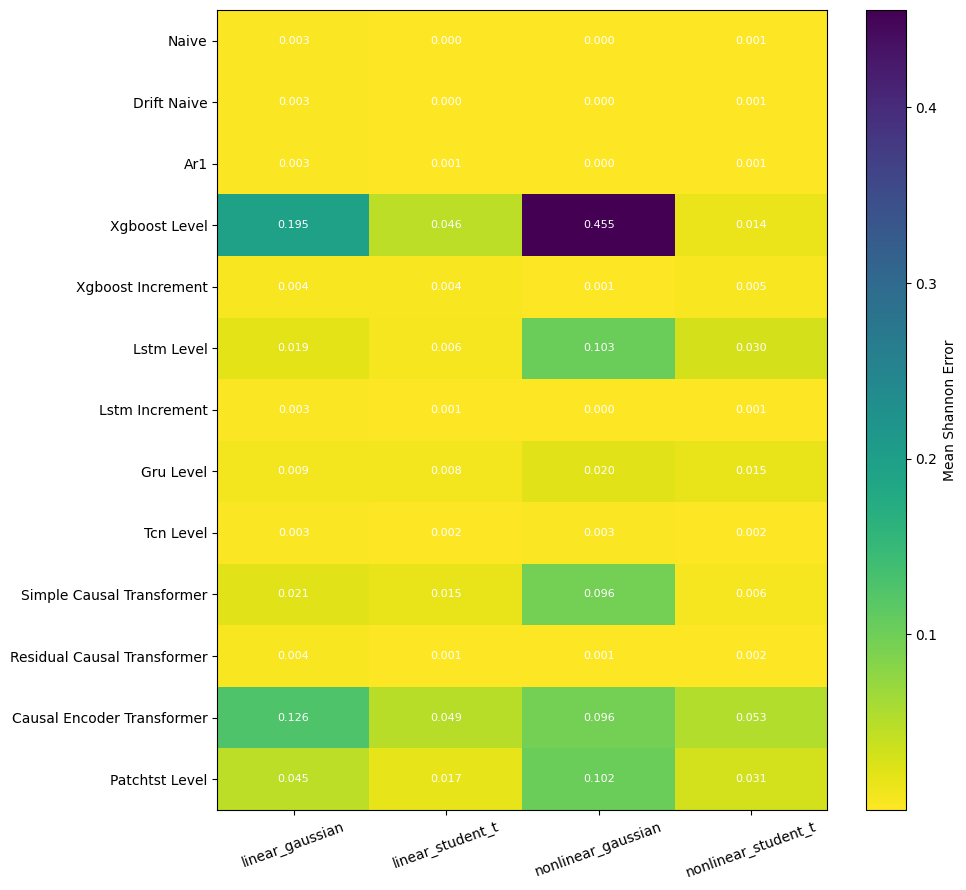

In [10]:
heatmap = summary_df.pivot(
    index="model",
    columns="series",
    values="mean_delta_shannon_entropy"
).reindex(MODEL_ORDER)

plt.figure(figsize=(10,9))

im = plt.imshow(
    heatmap.values,
    cmap="viridis_r",
    aspect="auto"
)

plt.xticks(
    np.arange(len(heatmap.columns)),
    heatmap.columns,
    rotation=20
)

plt.yticks(
    np.arange(len(heatmap.index)),
    [model_label(m) for m in heatmap.index]
)

plt.colorbar(label="Mean Shannon Error")

for i in range(heatmap.shape[0]):
    for j in range(heatmap.shape[1]):
        plt.text(
            j,
            i,
            f"{heatmap.values[i,j]:.3f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white"
        )

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "shannon_heatmap.png"
    ),
    dpi=300
)

plt.show()

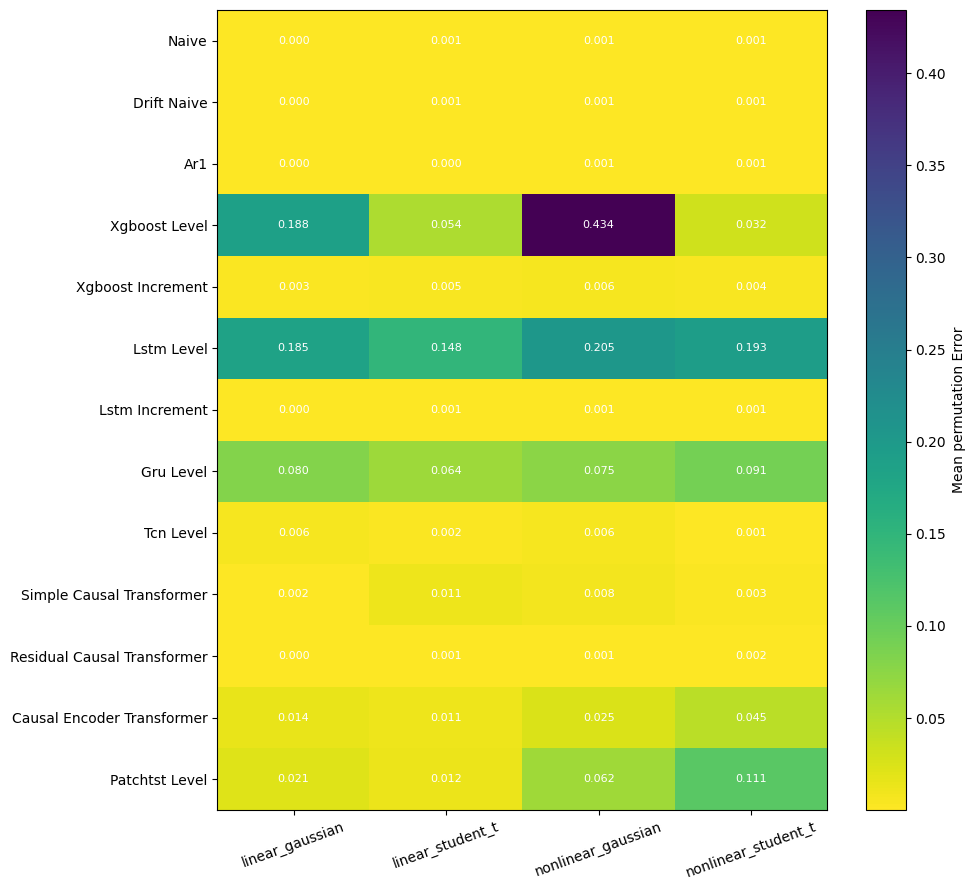

In [11]:
heatmap = summary_df.pivot(
    index="model",
    columns="series",
    values="mean_delta_permutation_entropy"
).reindex(MODEL_ORDER)

plt.figure(figsize=(10,9))

im = plt.imshow(
    heatmap.values,
    cmap="viridis_r",
    aspect="auto"
)

plt.xticks(
    np.arange(len(heatmap.columns)),
    heatmap.columns,
    rotation=20
)

plt.yticks(
    np.arange(len(heatmap.index)),
    [model_label(m) for m in heatmap.index]
)

plt.colorbar(label="Mean permutation Error")

for i in range(heatmap.shape[0]):
    for j in range(heatmap.shape[1]):
        plt.text(
            j,
            i,
            f"{heatmap.values[i,j]:.3f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white"
        )

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "permutation_heatmap.png"
    ),
    dpi=300
)

plt.show()

In [12]:
summary_df["entropy_score"] = (
    summary_df["mean_delta_shannon_entropy"] +
    summary_df["mean_delta_permutation_entropy"]
)

ranking = (
    summary_df
    .groupby("model")["entropy_score"]
    .mean()
    .sort_values()
)

ranking

model
drift_naive                    0.001627
naive                          0.001627
lstm_increment                 0.001930
ar1                            0.002068
residual_causal_transformer    0.003005
tcn_level                      0.006015
xgboost_increment              0.008092
simple_causal_transformer      0.040647
gru_level                      0.090738
patchtst_level                 0.100244
causal_encoder_transformer     0.104500
lstm_level                     0.222252
xgboost_level                  0.354612
Name: entropy_score, dtype: float64

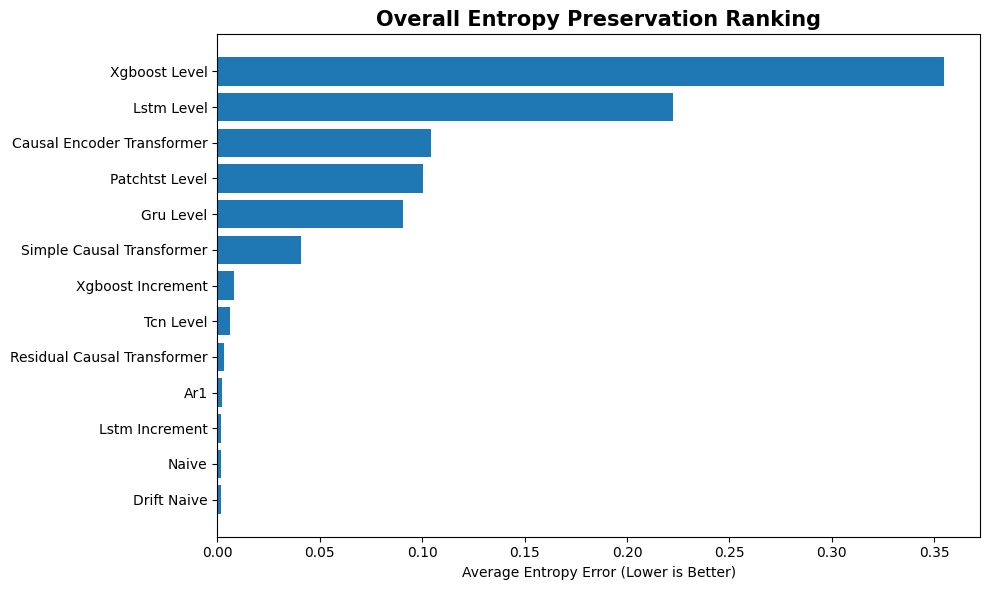

In [13]:
plt.figure(figsize=(10,6))

plt.barh(
    [model_label(x) for x in ranking.index],
    ranking.values
)

plt.xlabel(
    "Average Entropy Error (Lower is Better)"
)

plt.title(
    "Overall Entropy Preservation Ranking",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "overall_entropy_ranking.png"
    ),
    dpi=300
)

plt.show()

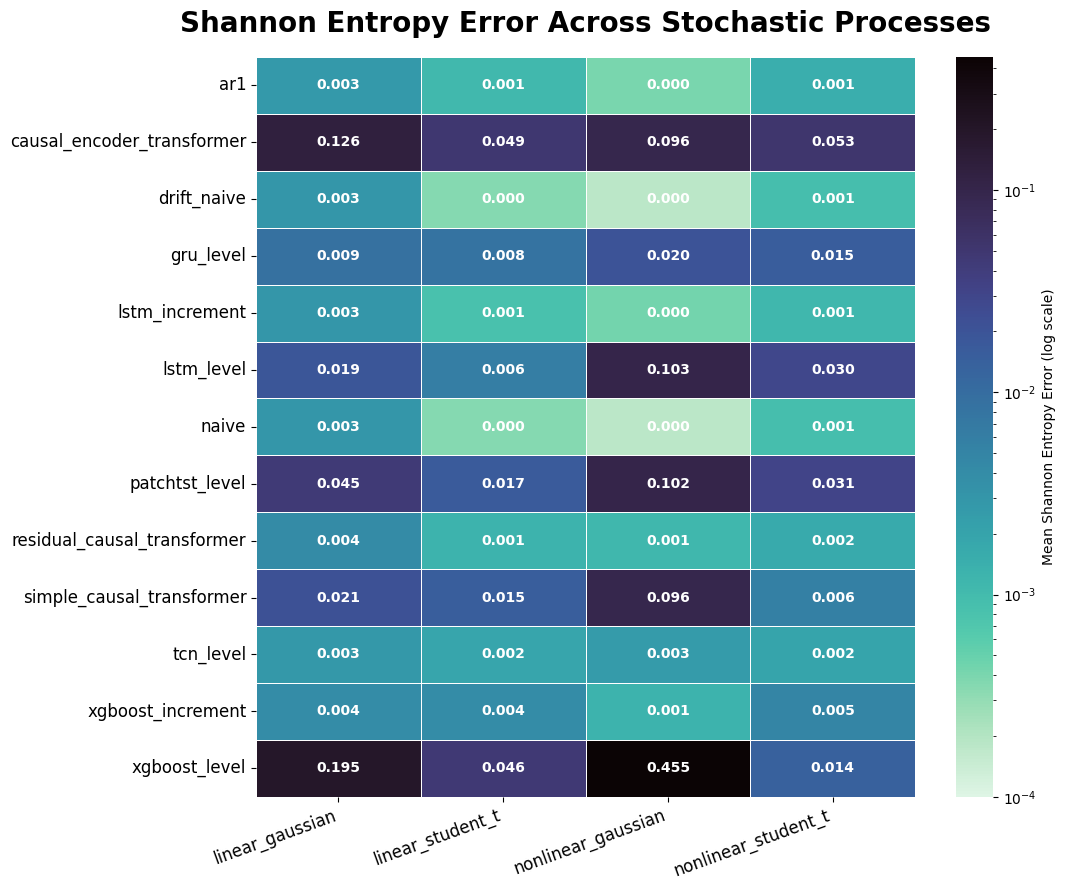

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# ===========================
# Load results
# ===========================

df = pd.read_csv(
    "C:\\Users\\user\\OneDrive\\Desktop\\noise_collapse_project\\results\\2026-06-25_full_benchmark\\entropy\\entropy_results_by_sigma.csv"
)

# ===========================
# Build heatmap table
# ===========================

shannon_heatmap = (
    df.groupby(["model", "series"])["delta_shannon_entropy"]
      .mean()
      .unstack()
)

shannon_heatmap = shannon_heatmap.sort_index()

# ===========================
# Plot
# ===========================

plt.figure(figsize=(11,9))

sns.heatmap(
    shannon_heatmap + 1e-5,
    cmap="mako_r",
    annot=True,
    fmt=".3f",
    annot_kws={
        "fontsize":10,
        "fontweight":"bold",
        "color":"white"
    },
    linewidths=0.5,
    linecolor="white",
    norm=LogNorm(
        vmin=1e-4,
        vmax=(shannon_heatmap + 1e-5).values.max()
    ),
    cbar_kws={
        "label":"Mean Shannon Entropy Error (log scale)"
    }
)

plt.title(
    "Shannon Entropy Error Across Stochastic Processes",
    fontsize=20,
    fontweight="bold",
    pad=18
)

plt.xlabel("")
plt.ylabel("")

plt.xticks(rotation=20, ha="right", fontsize=12)
plt.yticks(rotation=0, fontsize=12)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
    "shannon_entropy_heatmap_refined.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

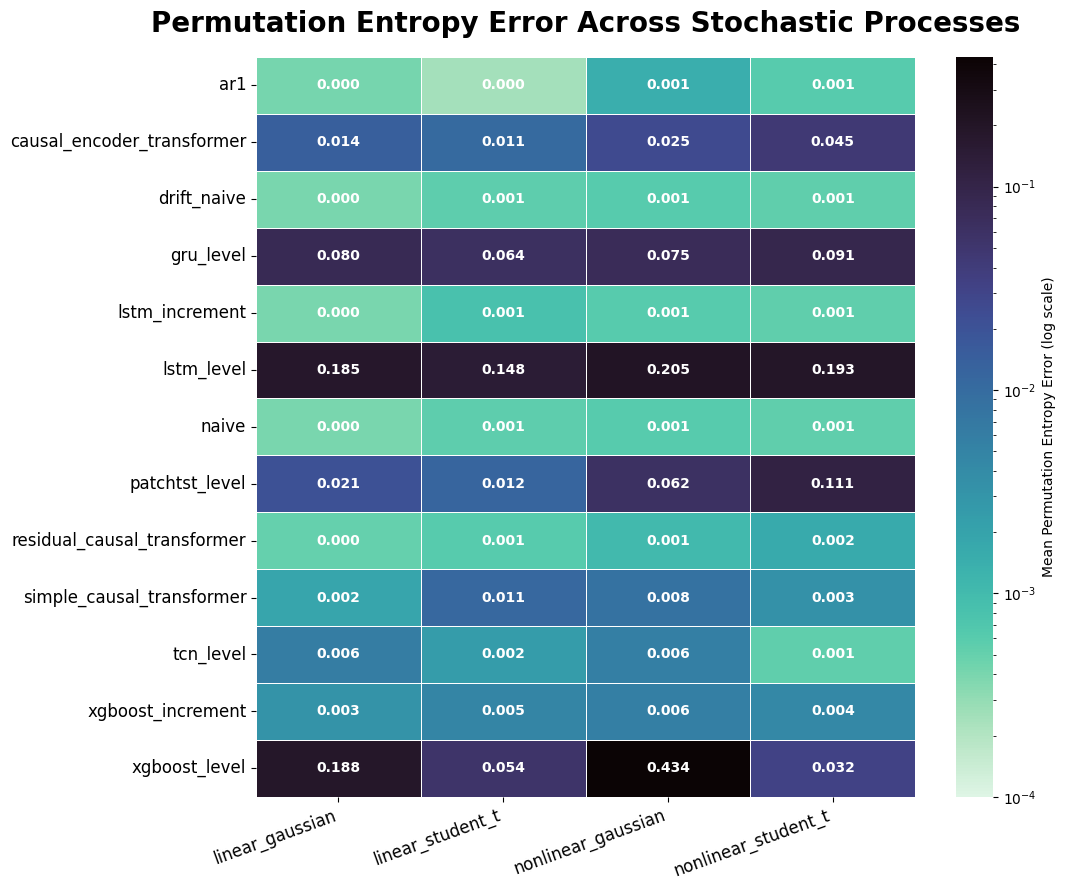

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# ===========================
# Load results
# ===========================

df = pd.read_csv(
    "C:\\Users\\user\\OneDrive\\Desktop\\noise_collapse_project\\results\\2026-06-25_full_benchmark\\entropy\\entropy_results_by_sigma.csv"
)

# ===========================
# Build heatmap table
# ===========================

permutation_heatmap = (
    df.groupby(["model", "series"])["delta_permutation_entropy"]
      .mean()
      .unstack()
)

# Sort models alphabetically (optional)
permutation_heatmap = permutation_heatmap.sort_index()

# ===========================
# Plot
# ===========================

plt.figure(figsize=(11,9))

sns.heatmap(
    permutation_heatmap + 1e-5,
    cmap="mako_r",
    annot=True,
    fmt=".3f",
    annot_kws={
        "fontsize":10,
        "fontweight":"bold",
        "color":"white"
    },
    linewidths=0.5,
    linecolor="white",
    norm=LogNorm(
        vmin=1e-4,
        vmax=(permutation_heatmap + 1e-5).values.max()
    ),
    cbar_kws={
        "label":"Mean Permutation Entropy Error (log scale)"
    }
)

plt.title(
    "Permutation Entropy Error Across Stochastic Processes",
    fontsize=20,
    fontweight="bold",
    pad=18
)

plt.xlabel("")
plt.ylabel("")

plt.xticks(rotation=20, ha="right", fontsize=12)
plt.yticks(rotation=0, fontsize=12)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
    "permutation_entropy_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()